# Evaluación Integradora – Parte 1
## Detección de objetos y análisis multi-cámara con YOLOv8

**Integrantes:** Dennis Nelson Fernández (Legajo 189692) y Marcos Andrés Wamba Ferreyra (Legajo 190802)

Este cuaderno implementa un pipeline de visión por computadora para la detección de objetos en una intersección urbana utilizando tres cámaras sincronizadas.

Los objetivos de esta primera etapa son:

- Sincronizar y analizar tres cámaras urbanas.
- Detectar personas y vehículos mediante YOLOv8.
- Identificar vehículos de color rojo.
- Generar registros estructurados de eventos.
- Unificar la información obtenida de las tres cámaras.
``

# 1. Preparación del entorno

En esta sección se instalan las librerías necesarias para ejecutar el proyecto.

Se utilizan principalmente:

- Ultralytics YOLOv8
- OpenCV
- NumPy
- Pandas
- Matplotlib

Estas herramientas permiten realizar la detección de objetos, análisis de color y generación de resultados.
`

In [1]:
!pip install ultralytics opencv-python-headless numpy pandas matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 23.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.5/95.5 kB 9.9 MB/s eta 0:00:00


Importar librerías

In [2]:
import cv2
import numpy as np
import pandas as pd
from ultralytics import YOLO
import matplotlib.pyplot as plt
from google.colab.patches import cv2_imshow

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


# 2. Selección de origen de datos

El cuaderno permite trabajar de dos maneras:

### Opción A (1)
Lectura directa desde Google Drive.

### Opción B (2)
Carga manual de videos y scripts.

Esto permite que el trabajo pueda ser ejecutado tanto por los integrantes del proyecto como por los evaluadores.

In [5]:
# ============================================================
# CONFIGURACIÓN DE ENTRADA: DRIVE o UPLOAD
# ============================================================

import os
import sys
from google.colab import drive, files

print("Seleccione modo de carga:")
print("1 = Usar archivos desde Google Drive (rápido, recomendado)")
print("2 = Subir archivos manualmente (para quienes no tienen acceso al Drive)")

modo = input("Ingrese 1 o 2: ").strip()

# ============================================================
# MODO 1: LEER DESDE GOOGLE DRIVE
# ============================================================

if modo == "1":
    print("\n🔵 Modo DRIVE seleccionado. Montando Google Drive...")

    drive.mount('/content/drive')

    # Ruta base en tu Drive
    BASE_DIR = "/content/drive/MyDrive/Intercambio_Estudio_UBP/VC/material_para_integrador"

    # Subcarpetas
    VIDEO_DIR = os.path.join(BASE_DIR, "videos")
    SCRIPT_DIR = os.path.join(BASE_DIR, "scripts")
    # Subcarpetas
    VIDEO_DIR = os.path.join(BASE_DIR, "PARTE1/videos")
    SCRIPT_DIR = os.path.join(BASE_DIR, "PARTE1/scripts")

    # Validación
    if not os.path.exists(VIDEO_DIR):
        raise FileNotFoundError(f"No existe la carpeta de videos: {VIDEO_DIR}")

    if not os.path.exists(SCRIPT_DIR):
        raise FileNotFoundError(f"No existe la carpeta de scripts: {SCRIPT_DIR}")

    # Agregar scripts al path
    sys.path.append(SCRIPT_DIR)

    print("\n📁 Videos disponibles:")
    print(os.listdir(VIDEO_DIR))

    print("\n📁 Scripts disponibles:")
    print(os.listdir(SCRIPT_DIR))

    print("\n✔ Drive montado y rutas configuradas correctamente.")


# ============================================================
# MODO 2: SUBIR ARCHIVOS MANUALMENTE
# ============================================================

elif modo == "2":
    print("\n🟠 Modo UPLOAD seleccionado. Suba los videos y scripts necesarios.")

    uploaded = files.upload()  # usuario sube videos y scripts

    # Crear carpetas locales
    VIDEO_DIR = "/content/videos"
    SCRIPT_DIR = "/content/scripts"

    os.makedirs(VIDEO_DIR, exist_ok=True)
    os.makedirs(SCRIPT_DIR, exist_ok=True)

    # Mover archivos subidos a carpetas correctas
    for fname in uploaded.keys():
        if fname.lower().endswith((".mp4", ".avi", ".mov")):
            os.rename(fname, os.path.join(VIDEO_DIR, fname))
        elif fname.lower().endswith(".py"):
            os.rename(fname, os.path.join(SCRIPT_DIR, fname))
        else:
            print(f"Archivo ignorado (no es video ni script): {fname}")

    # Agregar scripts al path
    sys.path.append(SCRIPT_DIR)

    print("\n📁 Videos cargados:")
    print(os.listdir(VIDEO_DIR))

    print("\n📁 Scripts cargados:")
    print(os.listdir(SCRIPT_DIR))

    print("\n✔ Archivos subidos y rutas configuradas correctamente.")


# ============================================================
# CONFIGURACIÓN FINAL
# ============================================================

print("\n🎯 Configuración completa. Puede ejecutar cualquiera de los pipelines:")
print(" - pipeline_calle.py")
print(" - pipeline_piso3.py")
print(" - pipeline_muni.py")

Seleccione modo de carga:
1 = Usar archivos desde Google Drive (rápido, recomendado)
2 = Subir archivos manualmente (para quienes no tienen acceso al Drive)
Ingrese 1 o 2: 1

🔵 Modo DRIVE seleccionado. Montando Google Drive...
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

📁 Videos disponibles:
['muni_fixed.mp4', 'calle_sync_1.mp4', 'piso3_sync_1.mp4', 'calle_1min.mp4', 'piso3_1min.mp4', 'muni_1min.mp4']

📁 Scripts disponibles:
['prueboyolo.py', 'utils_color.py', '__pycache__', 'pipeline_calle.py', 'pipeline_piso3.py', 'pipeline_muni.py', 'editor_yolo.py', 'pipeline_generico.py', 'camara_rois.py']

✔ Drive montado y rutas configuradas correctamente.

🎯 Configuración completa. Puede ejecutar cualquiera de los pipelines:
 - pipeline_calle.py
 - pipeline_piso3.py
 - pipeline_muni.py


# 3. Descripción de las cámaras utilizadas

El análisis se realiza sobre tres cámaras sincronizadas:

- **calle**: vista frontal a nivel de calle.
- **piso3**: vista elevada desde un edificio.
- **muni**: vista lateral municipal.

Los videos fueron normalizados a 30 FPS y posteriormente sincronizados mediante análisis visual y recorte temporal con FFmpeg.

(Alternativa para probar con videos de 10 minutos o de 1 minuto para las pruebas)


In [6]:
#Alternativa para probar con videos de 10 minutos o de 1 minuto para las pruebas
USE_SHORT_VIDEOS = True

if USE_SHORT_VIDEOS:
    VIDEO_CALLE = os.path.join(VIDEO_DIR, "calle_1min.mp4")
    VIDEO_PISO3 = os.path.join(VIDEO_DIR, "piso3_1min.mp4")
    VIDEO_MUNI  = os.path.join(VIDEO_DIR, "muni_1min.mp4")
else:
    VIDEO_CALLE = os.path.join(VIDEO_DIR, "calle_sync_1.mp4")
    VIDEO_PISO3 = os.path.join(VIDEO_DIR, "piso3_sync_1.mp4")
    VIDEO_MUNI  = os.path.join(VIDEO_DIR, "muni_fixed.mp4")

# 4. Configuración operativa y escenario de despliegue

Durante la etapa inicial de desarrollo, los videos fueron normalizados a **30 FPS** con el objetivo de facilitar las tareas de sincronización temporal y validación visual entre las distintas cámaras.

Posteriormente, y a partir de las observaciones realizadas por el docente durante la revisión del proyecto, se reconsideraron los parámetros de operación pensando en una posible implementación real del sistema.

## Frecuencia de procesamiento propuesta

Se adoptó una configuración de:

- Resolución: **1280 × 720 píxeles**
- Frecuencia: **15 FPS**

La elección de 15 FPS permite reducir aproximadamente un 50% la carga computacional respecto de 30 FPS, manteniendo una calidad suficiente para:

- detección de vehículos,
- clasificación de objetos,
- identificación de color,
- tracking de trayectorias,
- análisis de tránsito urbano.

Dado que el objetivo del proyecto no requiere reconocimiento facial ni análisis de movimientos de alta velocidad, se considera que 15 FPS representa un equilibrio adecuado entre rendimiento y precisión.

## Escenario de referencia para una implementación municipal

Se consideró un escenario compuesto por:

- 5 intersecciones urbanas.
- 3 cámaras por intersección.
- 15 cámaras procesadas de forma simultánea.

Para un despliegue de estas características se propone una estación de procesamiento con la siguiente configuración mínima:

| Componente | Configuración propuesta |
|------------|-------------------------|
| CPU | AMD Ryzen 9 9950X o equivalente |
| Memoria RAM | 64 GB DDR5 |
| GPU | NVIDIA RTX 4080 Super |
| Almacenamiento | SSD NVMe 2 TB |
| Sistema Operativo | Ubuntu Server LTS |

Esta infraestructura permitiría ejecutar los modelos de visión por computadora sobre múltiples cámaras urbanas en forma simultánea, manteniendo capacidad de crecimiento para futuras funcionalidades de tracking e integración multi-cámara.

# 5. Detección de objetos con YOLOv8

Se utiliza el modelo YOLOv8 para detectar:

- Personas
- Automóviles
- Motocicletas
- Bicicletas
- Camiones

Para cada detección se registran:

- Clase detectada
- Timestamp
- Bounding Box normalizado
- Cámara de origen

In [9]:
from pipeline_calle import procesar_calle
from pipeline_piso3 import procesar_piso3
from pipeline_muni import procesar_muni
import pandas as pd

RESULTADOS_DIR = os.path.join(BASE_DIR, "resultados")
os.makedirs(RESULTADOS_DIR, exist_ok=True)

CSV_CALLE = os.path.join(RESULTADOS_DIR, "eventos_calle.csv")
CSV_PISO3 = os.path.join(RESULTADOS_DIR, "eventos_piso3.csv")
CSV_MUNI = os.path.join(RESULTADOS_DIR, "eventos_muni.csv")
CSV_TOTAL = os.path.join(RESULTADOS_DIR, "eventos_total.csv")

# 6. Identificación de vehículos rojos

Además de la detección de objetos, se implementa un análisis de color basado en HSV.

El criterio utilizado combina:

- Porcentaje de píxeles rojos.
- Distribución espacial del rojo (spread).

Este enfoque permite evitar falsos positivos producidos por luces de freno o reflejos.

In [10]:
from utils_color import is_red_vehicle # Import the missing function

In [11]:
import pipeline_generico

print(pipeline_generico.__file__)

/content/drive/MyDrive/Intercambio_Estudio_UBP/VC/material_para_integrador/PARTE1/scripts/pipeline_generico.py


In [12]:
import importlib

import pipeline_generico
import pipeline_muni
import pipeline_calle
import pipeline_piso3

importlib.reload(pipeline_generico)
importlib.reload(pipeline_muni)
importlib.reload(pipeline_calle)
importlib.reload(pipeline_piso3)

<module 'pipeline_piso3' from '/content/drive/MyDrive/Intercambio_Estudio_UBP/VC/material_para_integrador/PARTE1/scripts/pipeline_piso3.py'>

# 7. Procesamiento de las tres cámaras

Cada cámara es procesada individualmente mediante un pipeline común.

Como resultado se genera un archivo CSV por cámara con todos los eventos detectados.

Posteriormente los tres conjuntos de datos se unifican para facilitar el análisis global.

In [13]:
procesar_calle(VIDEO_CALLE,CSV_CALLE)
procesar_piso3(VIDEO_PISO3, CSV_PISO3)
procesar_muni(VIDEO_MUNI, CSV_MUNI)

df_calle = pd.read_csv(CSV_CALLE)
df_piso3 = pd.read_csv(CSV_PISO3)
df_muni = pd.read_csv(CSV_MUNI)



Se han truncado las últimas 5000 líneas del flujo de salida.
VERIFICANDO muni car xc=0.718 yc=0.935
VERIFICANDO muni car xc=0.470 yc=0.584
VERIFICANDO muni car xc=0.368 yc=0.628
VERIFICANDO muni car xc=0.472 yc=0.714
VERIFICANDO muni car xc=0.907 yc=0.593
VERIFICANDO muni car xc=0.687 yc=0.395
VERIFICANDO muni car xc=0.879 yc=0.562
VERIFICANDO muni person xc=0.677 yc=0.866
VERIFICANDO muni person xc=0.558 yc=0.979
VERIFICANDO muni car xc=0.441 yc=0.649
VERIFICANDO muni car xc=0.914 yc=0.474
VERIFICANDO muni truck xc=0.441 yc=0.647
VERIFICANDO muni person xc=0.677 yc=0.858
VERIFICANDO muni car xc=0.783 yc=0.485
ROI HIT muni contenedor_obra 0.7827872633934021 0.48468485474586487
EXCLUIDO -> muni car (0.783,0.485)
VERIFICANDO muni car xc=0.913 yc=0.469

0: 384x640 3 persons, 17 cars, 1 truck, 10.1ms
Speed: 3.6ms preprocess, 10.1ms inference, 1.7ms postprocess per image at shape (1, 3, 384, 640)
VERIFICANDO muni car xc=0.840 yc=0.673
VERIFICANDO muni car xc=0.796 yc=0.915
VERIFICANDO muni 

# 8. Integración multi-cámara

Los eventos obtenidos de cada cámara se combinan en un único DataFrame denominado **df_total**.

La columna *camera* permite identificar el origen de cada detección.

Este conjunto de datos constituye la base de trabajo para los análisis posteriores.

In [14]:
df_total = pd.concat(
    [df_calle, df_piso3, df_muni],
    ignore_index=True
)
#Guardamos el csv inmediatamente
df_total.to_csv(
os.path.join(RESULTADOS_DIR, "eventos_total.csv"),
index=False
)

# 9. Evidencia visual de las detecciones

Se selecciona un frame específico y se visualiza simultáneamente en las tres cámaras.

Sobre cada imagen se dibujan:

- Bounding Boxes detectadas por YOLO.
- Clasificación del objeto.
- Vehículos rojos identificados mediante el módulo de color.

Las imágenes resultantes también se almacenan automáticamente en la carpeta **evidencia**.

In [15]:
#Crear carpeta evidencia
EVIDENCIA_DIR = os.path.join(BASE_DIR, "evidencia")
os.makedirs(EVIDENCIA_DIR, exist_ok=True)

In [16]:
import cv2
import matplotlib.pyplot as plt
import os
from ultralytics import YOLO # Import YOLO if not already imported in a previous cell

<IPython.core.display.Javascript object>

Ingrese frame a visualizar: 930

0: 384x640 4 cars, 8.9ms
Speed: 1.4ms preprocess, 8.9ms inference, 1.2ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 1 person, 12 cars, 9.1ms
Speed: 1.8ms preprocess, 9.1ms inference, 1.6ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 2 persons, 8 cars, 9.0ms
Speed: 2.1ms preprocess, 9.0ms inference, 1.5ms postprocess per image at shape (1, 3, 384, 640)


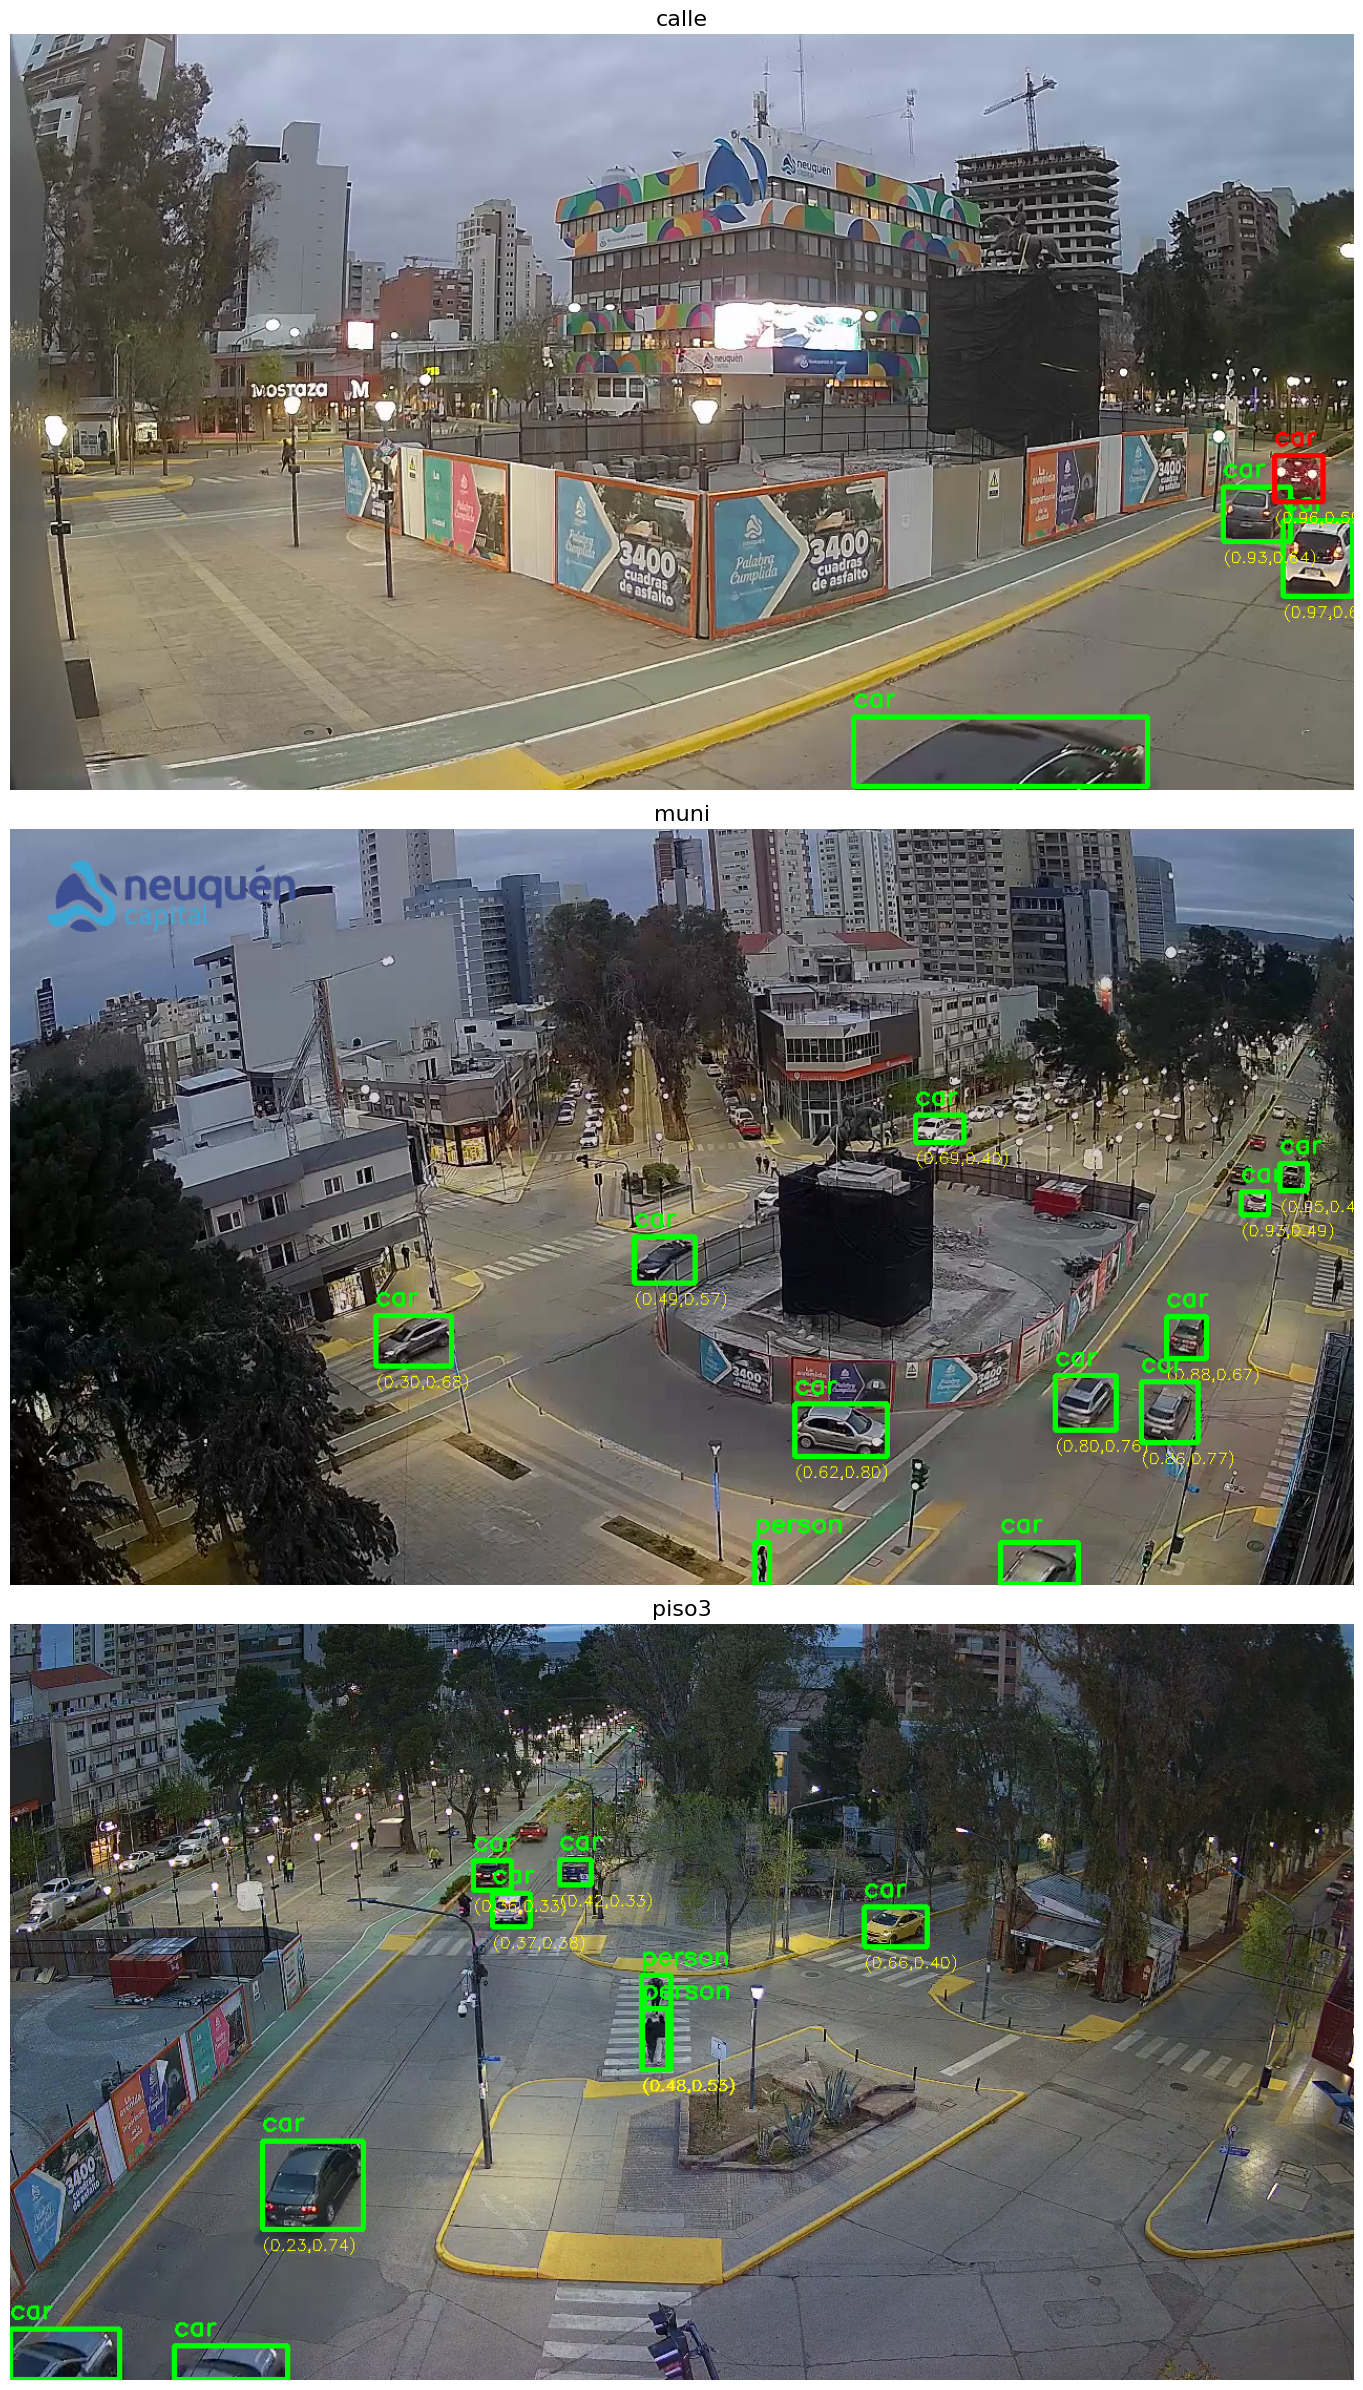

✅ PNG guardados en: /content/drive/MyDrive/Intercambio_Estudio_UBP/VC/material_para_integrador/evidencia


In [23]:
import cv2
import matplotlib.pyplot as plt
import os
from ultralytics import YOLO
from camara_rois import CAMERA_CONFIG
from google.colab import output

# Desactivar la barra de scroll vertical de la salida en Colab
output.no_vertical_scroll()

def inside_exclusion_zone(camera_name, xc, yc):
    """
    Checks if a given (xc, yc) point is inside any exclusion zone for a specific camera.
    Args:
        camera_name (str): The name of the camera (e.g., 'muni', 'piso3', 'calle').
        xc (float): Normalized x-coordinate of the object's center.
        yc (float): Normalized y-coordinate of the object's center.
    Returns:
        bool: True if the point is inside an exclusion zone, False otherwise.
    """
    if camera_name in CAMERA_CONFIG and "exclusion_zones" in CAMERA_CONFIG[camera_name]:
        for zone in CAMERA_CONFIG[camera_name]["exclusion_zones"]:
            x1, y1, x2, y2 = zone["x1"], zone["y1"], zone["x2"], zone["y2"]
            if x1 <= xc <= x2 and y1 <= yc <= y2:
                return True
    return False

# =========================================
# FRAME A VISUALIZAR
# =========================================

FRAME_TO_SHOW = int(input("Ingrese frame a visualizar: "))

videos = {
    "calle": os.path.join(VIDEO_DIR, VIDEO_CALLE),
    "muni": os.path.join(VIDEO_DIR, VIDEO_MUNI),
    "piso3": os.path.join(VIDEO_DIR, VIDEO_PISO3)
}

# Initialize the YOLO model
model = YOLO('yolov8n.pt')

# Define CLASSES_INTERES
CLASSES_INTERES = ["person", "car", "motorcycle", "bus", "truck", "bicycle"]

# Creamos la figura con un tamaño expandido para ver las 3 imágenes completas y grandes
fig, axes = plt.subplots(3, 1, figsize=(16, 24))
for ax, (camera_name, video_path) in zip(axes, videos.items()):

    cap = cv2.VideoCapture(video_path)
    cap.set(cv2.CAP_PROP_POS_FRAMES, FRAME_TO_SHOW)
    ret, frame = cap.read()
    cap.release()

    if not ret:
        ax.set_title(f"{camera_name} - Frame no encontrado")
        ax.axis("off")
        continue

    h, w, _ = frame.shape
    results = model(frame)[0]

    for box in results.boxes:
        cls_idx = int(box.cls[0])
        clase_nombre = model.names[cls_idx]

        if clase_nombre not in CLASSES_INTERES:
            continue

        xc, yc, bw, bh = box.xywhn[0].tolist()
        # excluir zonas prohibidas
        if inside_exclusion_zone(camera_name, xc, yc):
            continue
        x_center = int(xc * w)
        y_center = int(yc * h)

        box_w = int(bw * w)
        box_h = int(bh * h)

        x1 = max(0, x_center - box_w // 2)
        y1 = max(0, y_center - box_h // 2)
        x2 = min(w, x_center + box_w // 2)
        y2 = min(h, y_center + box_h // 2)

        roi = frame[y1:y2, x1:x2]
        is_red = False

        if clase_nombre in ["car", "motorcycle", "bicycle", "truck"]:
            is_red = is_red_vehicle(
                roi,
                ratio_threshold=0.12,
                spread_threshold=0.25
            )

        color = (0, 255, 0)
        if is_red:
            color = (0, 0, 255)

        cv2.rectangle(frame, (x1, y1), (x2, y2), color, 3) # Grosor de línea aumentado para mejor visualización

        cv2.putText(
            frame,
            clase_nombre,
            (x1, y1 - 10),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.8,
            color,
            2
        )
        cv2.putText(
            frame,
            f"({xc:.2f},{yc:.2f})",
            (x1, y2 + 20),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.5,
            (0,255,255),
            1
        )

    # =========================================
    # GUARDAR PNG EN EVIDENCIA
    # =========================================
    png_name = f"{camera_name}_frame_{FRAME_TO_SHOW}.png"
    cv2.imwrite(
        os.path.join(EVIDENCIA_DIR, png_name),
        frame
    )

    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    ax.imshow(rgb)
    ax.set_title(camera_name, fontsize=16)
    ax.axis("off")

plt.tight_layout()
plt.show()
print(f"✅ PNG guardados en: {EVIDENCIA_DIR}")

In [24]:
import os

# Path to camara_rois.py (using SCRIPT_DIR defined previously)
camara_rois_path = os.path.join(SCRIPT_DIR, 'camara_rois.py')

print(f"Content of {camara_rois_path}:\n")
with open(camara_rois_path, 'r') as f:
    print(f.read())

Content of /content/drive/MyDrive/Intercambio_Estudio_UBP/VC/material_para_integrador/PARTE1/scripts/camara_rois.py:

CAMERA_CONFIG = {
    "muni": {
        "exclusion_zones": [
            {
                "name": "contenedor_obra",
                "x1": 0.76,
                "y1": 0.46,
                "x2": 0.80,
                "y2": 0.51
            },
            {
                "name": "monumento_san_martin",
                "x1": 0.57,
                "y1": 0.43,
                "x2": 0.69,
                "y2": 0.66
            }            
        ],
        "landmarks": [
        {
            "name": "monumento_san_martin",
                "x1": 0.57,
                "y1": 0.43,
                "x2": 0.69,
                "y2": 0.66
            }
        ]
    },

    "piso3": {

        "exclusion_zones": [

            {
                "name": "contenedor_obra",
                "x1": 0.07,
                "y1": 0.40,
                "x2": 0.14,
                "y2":

# 10. Resumen de resultados

A continuación se presentan algunos indicadores básicos obtenidos a partir de las detecciones:

- Cantidad total de eventos.
- Distribución por tipo de objeto.
- Vehículos rojos detectados.
- Distribución por cámara.

Eventos totales: 37114


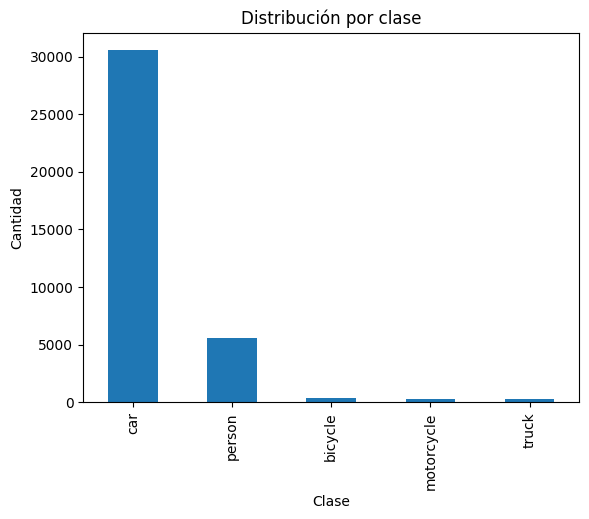

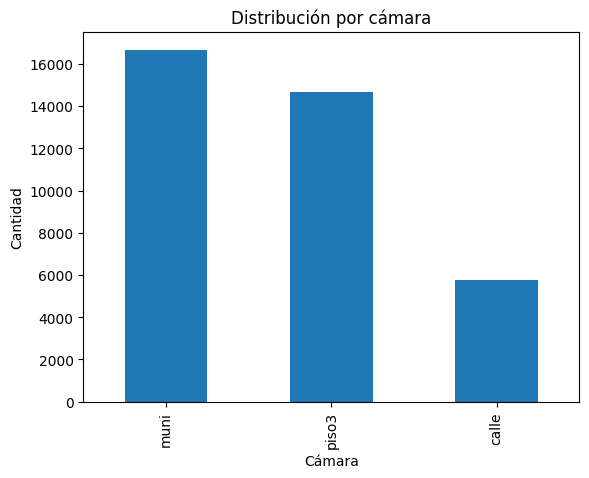

7.37% de los vehículos detectados fueron clasificados como rojos


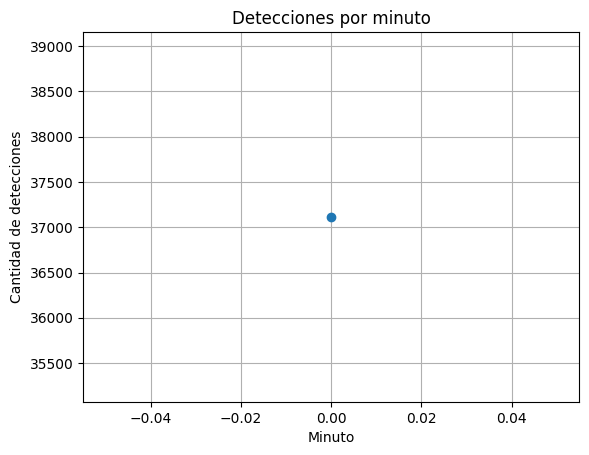

Personas detectadas: 5624
Vehículos detectados: 31490
Objeto más frecuente: car
Cámara con más detecciones: muni


In [25]:
print("Eventos totales:", len(df_total))
df_total["class"].value_counts()

import matplotlib.pyplot as plt

df_total["class"].value_counts().plot(kind="bar")
plt.title("Distribución por clase")
plt.xlabel("Clase")
plt.ylabel("Cantidad")
plt.show()

df_total["camera"].value_counts().plot(kind="bar")
plt.title("Distribución por cámara")
plt.xlabel("Cámara")
plt.ylabel("Cantidad")
plt.show()

df_total[df_total.is_red].shape[0]

df_total[df_total.is_red]["class"].value_counts()

vehiculos = ["car", "truck", "motorcycle", "bicycle"]

df_veh = df_total[df_total["class"].isin(vehiculos)]

total_veh = len(df_veh)
rojos = len(df_veh[df_veh["is_red"]])

print(
    f"{rojos/total_veh*100:.2f}% de los vehículos detectados fueron clasificados como rojos"
)

df_total["minuto"] = (df_total["timestamp_s"] // 60).astype(int)

df_total.groupby("minuto").size()

df_total.groupby("minuto").size().plot(marker="o")
plt.title("Detecciones por minuto")
plt.xlabel("Minuto")
plt.ylabel("Cantidad de detecciones")
plt.grid()
plt.show()

personas = len(df_total[df_total["class"] == "person"])

print("Personas detectadas:", personas)
vehiculos = len(
    df_total[
        df_total["class"].isin(
            ["car","truck","motorcycle","bicycle"]
        )
    ]
)

print("Vehículos detectados:", vehiculos)
pd.crosstab(
    df_total["camera"],
    df_total["class"]
)
objeto_mas_comun = df_total["class"].value_counts().idxmax()

print("Objeto más frecuente:", objeto_mas_comun)
camara_mas_activa = df_total["camera"].value_counts().idxmax()

print("Cámara con más detecciones:", camara_mas_activa)

In [26]:
print("==== RESUMEN ====")
print("Eventos totales:", len(df_total))
print("Personas:", len(df_total[df_total["class"]=="person"]))
print("Vehículos:", len(df_total[df_total["class"].isin(["car","truck","motorcycle","bicycle"])]))
print("Vehículos rojos:", len(df_total[df_total["is_red"]]))
print("Cámara más activa:", df_total["camera"].value_counts().idxmax())
print("Clase más frecuente:", df_total["class"].value_counts().idxmax())

==== RESUMEN ====
Eventos totales: 37114
Personas: 5624
Vehículos: 31490
Vehículos rojos: 2321
Cámara más activa: muni
Clase más frecuente: car


In [ ]:
#ver los 5 primereos con rojo
df_red = df_total[df_total.is_red]
print("Vehículos rojos detectados:", len(df_red))
df_red.head()

Vehículos rojos detectados: 2321


,timestamp_s,frame,camera,local_id,class,is_red,xc,yc,bw,bh,minuto
1358,25.433333,763,calle,6,car,True,0.234550,0.592249,0.029338,0.040676,0
1363,25.466667,764,calle,5,car,True,0.232720,0.592470,0.032515,0.046107,0
1368,25.500000,765,calle,4,car,True,0.231113,0.591166,0.036094,0.050302,0
1374,25.533333,766,calle,4,car,True,0.230562,0.589524,0.037757,0.053183,0
1381,25.566667,767,calle,4,car,True,0.228938,0.587584,0.041300,0.058991,0


# Trabajo futuro y transición a la Parte 2

La presente etapa tuvo como objetivo principal validar la adquisición de datos, sincronización de cámaras, detección de objetos, análisis de color y generación de eventos estructurados.

Durante el desarrollo se construyó además un dataset propio compuesto por **588 imágenes etiquetadas manualmente**, que constituye la base para la siguiente fase del proyecto.

Por sugerencia del docente, en la Parte 2 se realizará una evolución del esquema de clasificación vehicular originalmente utilizado.

## Clases empleadas en la Parte 1

- person
- car
- motorcycle
- bicycle
- truck

## Clases objetivo para la Parte 2

- person
- automovil
- utilitario
- pickup
- camion
- motorcycle
- bicycle

Esta reclasificación permitirá entrenar un modelo especializado para tránsito urbano y avanzar hacia un sistema capaz de identificar:

```text
track_id
tipo de vehículo
color